# Entregable — Generación de Texto con Transformers (Puntos 1, 2 y 3)

**Universidad Autónoma de Occidente — IA Generativa 2026-2S** · Sergio Gómez — Valeria Franco

Notebook unificado con los tres puntos ya ejecutados en Colab (GPU T4) y sus salidas. Cada punto es independiente: para re-ejecutar uno, reinicia el entorno y corre solo su sección.

- Punto 1: Char-Llama sobre *Don Quijote*
- Punto 2: Word-Llama sobre *Don Quijote*
- Punto 3: RAG con Ollama

---
# PUNTO 1

# Punto 1 — Generación de texto a nivel de **carácter** con un Transformer tipo **Llama**

UNIVERSIDAD AUTÓNOMA DE OCCIDENTE — Inteligencia Artificial Generativa 2026-2S  
Entregable: *Modelos Generativos de Texto Basados en la Arquitectura Transformer*  
**Integrantes:** Sergio Gómez — Valeria Franco

**Objetivo:** cambiar el corpus de Shakespeare por otro (aquí *Don Quijote*) y entrenar un
modelo *Char GPT* cuya arquitectura sea la de **Llama** (RMSNorm + RoPE + SwiGLU, sin bias),
evaluando con métricas adecuadas para modelos de lenguaje.

> Ejecutar en Colab con **GPU (T4)**: *Entorno de ejecución → Cambiar tipo → GPU*.

In [1]:
import os, sys, re, math, time, collections
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Modo rápido (solo para pruebas locales sin GPU): RAPIDO=1 reduce corpus y épocas
RAPIDO = os.environ.get("RAPIDO", "0") == "1"
tf.random.set_seed(42); np.random.seed(42)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Corpus: *Don Quijote de la Mancha* (Miguel de Cervantes)

Reemplazamos las obras de Shakespeare por el texto completo de **Don Quijote de la Mancha**
(Proyecto Gutenberg, libro #2000, dominio público). Es un corpus en **español** de ~2 millones
de caracteres, de tamaño comparable al de Shakespeare (~1.1 M), con diálogos y narración,
lo que lo hace adecuado para un modelo de lenguaje pequeño.

In [2]:
url = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
filepath = tf.keras.utils.get_file("quijote.txt", url)
with open(filepath, encoding="utf-8") as f:
    raw = f.read()

# Quitamos la cabecera y la licencia de Gutenberg
start = raw.find("*** START OF"); start = raw.find("\n", start) + 1
end = raw.find("*** END OF")
text = raw[start:end].strip()
text = re.sub(r"\r", "", text)
text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)   # une las líneas cortadas a ~70 columnas
text = re.sub(r"\n{2,}", "\n", text)           # un salto de línea = cambio de párrafo
text = re.sub(r" {2,}", " ", text)
if RAPIDO:
    text = text[:200_000]
print(f"Caracteres: {len(text):,}")
print(text[5000:5600])

2225803/2225803 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Caracteres: 2,104,974
s los que llevaban a don Quijote
De la pendencia que don Quijote tuvo con el cabrero, con la rara aventura de los deceplinantes, a quien dio felice fin a costa de su sudor
Segunda parte del ingenioso caballero don Quijote de la Mancha
 Tasa
 Fee de erratas
 Aprobaciones
 Dedicatoria, al conde de Lemos
 Prólogo al lector
De lo que el cura y el barbero pasaron con don Quijote cerca de su enfermedad
Que trata de la notable pendencia que Sancho Panza tuvo con la sobrina y ama de don Quijote, con otros sujetos graciosos
Del ridículo razonamiento que pasó entre don Quijote, Sancho Panza y el bachill


## 2. Tokenización a nivel de carácter

Igual que en el notebook de clase usamos `TextVectorization(split="character")`, en
minúsculas, y descartamos los tokens 0 (`PAD`) y 1 (`UNK`).

In [3]:
text_vec_layer = tf.keras.layers.TextVectorization(split="character", standardize="lower")
text_vec_layer.adapt([text])
vocab = text_vec_layer.get_vocabulary()
encoded = text_vec_layer([text])[0].numpy() - 2      # quitamos PAD/UNK
n_tokens = len(vocab) - 2
print("Vocabulario (caracteres):", n_tokens)
print("".join(vocab[2:]))

Vocabulario (caracteres): 68
 eaosnrlduitcm,pqybhvgíjó.fáé—z
;ñ:ú?¿'!¡x»"É-ü)(«ÁÍ1ÚÓï6ùw]40àÑ7532


Particionamos el texto de forma **contigua** (90 % entrenamiento, 5 % validación,
5 % prueba) para que la evaluación sea sobre texto nunca visto.

In [4]:
def to_dataset(sequence, length, shift=1, shuffle=False, seed=None, batch_size=64):
    """Ventanas de length+1 tokens -> (entrada = x[:-1], objetivo = x[1:])."""
    ds = tf.data.Dataset.from_tensor_slices(sequence)
    ds = ds.window(length + 1, shift=shift, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(length + 1))
    if shuffle:
        ds = ds.shuffle(20_000, seed=seed)
    ds = ds.batch(batch_size)
    return ds.map(lambda w: (w[:, :-1], w[:, 1:])).prefetch(tf.data.AUTOTUNE)

LENGTH = 128                     # contexto del modelo (caracteres)
n = len(encoded)
i_tr, i_va = int(n * 0.90), int(n * 0.95)
# shift=LENGTH//4 para que una época no tenga millones de ventanas casi idénticas
train_set = to_dataset(encoded[:i_tr], LENGTH, shift=LENGTH // 4, shuffle=True, seed=42)
valid_set = to_dataset(encoded[i_tr:i_va], LENGTH, shift=LENGTH)
test_set = to_dataset(encoded[i_va:], LENGTH, shift=LENGTH)

for x, y in train_set.take(1):
    dec = lambda ids: "".join(vocab[i + 2] for i in ids)
    print("Entrada :", repr(dec(x[0].numpy()[:60])))
    print("Objetivo:", repr(dec(y[0].numpy()[:60])))

Entrada : ' caballeriza.\ny, habiendo andado como dos millas, descubrió '
Objetivo: 'caballeriza.\ny, habiendo andado como dos millas, descubrió d'


## Arquitectura Transformer tipo Llama

El Char-Transformer de clase usa la parte **decodificadora** de un Transformer "clásico"
(GPT-2/Vaswani): embeddings posicionales aprendidos, `LayerNormalization` *post-norm*,
FFN con ReLU. La familia **Llama** (Touvron et al., 2023) introduce cuatro cambios que aquí
implementamos desde cero en Keras:

| Componente | Transformer clásico | Llama (este notebook) |
|---|---|---|
| Normalización | LayerNorm (post-norm) | **RMSNorm** (pre-norm) |
| Posición | Embedding posicional absoluto sumado | **RoPE** – rotación de *queries/keys* |
| Red feed-forward | Dense → ReLU → Dense | **SwiGLU**: `W2(SiLU(W1·x) ⊙ W3·x)` |
| Sesgos (*bias*) | Sí | **No** (todas las capas lineales sin bias) |

Además la atención es **causal** (cada posición solo ve las anteriores), por lo que el modelo
es autorregresivo: `P(x_t | x_<t)`.

In [5]:
import keras
from keras import layers, ops


@keras.saving.register_keras_serializable(package="llama")
class RMSNorm(layers.Layer):
    """Root Mean Square Norm: x / sqrt(mean(x^2) + eps) * g  (sin centrar ni bias)."""
    def __init__(self, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        self.scale = self.add_weight(name="scale", shape=(input_shape[-1],), initializer="ones")

    def call(self, x):
        ms = ops.mean(ops.square(x), axis=-1, keepdims=True)
        return x * ops.rsqrt(ms + self.eps) * self.scale

    def get_config(self):
        return {**super().get_config(), "eps": self.eps}


def rope(x, base=10000.0):
    """Rotary Positional Embedding. x: (batch, heads, seq, head_dim)."""
    seq_len, head_dim = ops.shape(x)[2], ops.shape(x)[3]
    half = head_dim // 2
    inv_freq = 1.0 / (base ** (ops.cast(ops.arange(half), "float32") / half))
    pos = ops.cast(ops.arange(seq_len), "float32")
    angles = ops.einsum("i,j->ij", pos, inv_freq)            # (seq, half)
    cos, sin = ops.cos(angles), ops.sin(angles)
    cos, sin = ops.cast(cos, x.dtype), ops.cast(sin, x.dtype)
    x1, x2 = x[..., :half], x[..., half:]
    return ops.concatenate([x1 * cos - x2 * sin, x1 * sin + x2 * cos], axis=-1)


@keras.saving.register_keras_serializable(package="llama")
class CausalSelfAttentionRoPE(layers.Layer):
    """Atención multi-cabeza causal con RoPE y proyecciones sin bias."""
    def __init__(self, d_model, n_heads, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.n_heads, self.dropout_rate = d_model, n_heads, dropout
        self.head_dim = d_model // n_heads
        self.wq = layers.Dense(d_model, use_bias=False)
        self.wk = layers.Dense(d_model, use_bias=False)
        self.wv = layers.Dense(d_model, use_bias=False)
        self.wo = layers.Dense(d_model, use_bias=False)
        self.drop = layers.Dropout(dropout)

    def _split(self, x, b, t):
        x = ops.reshape(x, (b, t, self.n_heads, self.head_dim))
        return ops.transpose(x, (0, 2, 1, 3))                   # (b, h, t, hd)

    def call(self, x, training=False):
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        q = rope(self._split(self.wq(x), b, t))
        k = rope(self._split(self.wk(x), b, t))
        v = self._split(self.wv(x), b, t)
        scores = ops.matmul(q, ops.transpose(k, (0, 1, 3, 2))) / ops.sqrt(ops.cast(self.head_dim, x.dtype))
        mask = ops.tril(ops.ones((t, t), dtype="bool"))          # máscara causal
        scores = ops.where(mask, scores, ops.cast(-1e9, scores.dtype))
        att = self.drop(ops.softmax(scores, axis=-1), training=training)
        out = ops.transpose(ops.matmul(att, v), (0, 2, 1, 3))
        return self.wo(ops.reshape(out, (b, t, self.d_model)))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "n_heads": self.n_heads,
                "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="llama")
class SwiGLU(layers.Layer):
    """FFN de Llama: W2( SiLU(W1 x) * W3 x ), sin bias."""
    def __init__(self, d_model, hidden, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.hidden = d_model, hidden
        self.w1 = layers.Dense(hidden, use_bias=False)
        self.w3 = layers.Dense(hidden, use_bias=False)
        self.w2 = layers.Dense(d_model, use_bias=False)

    def call(self, x):
        return self.w2(ops.silu(self.w1(x)) * self.w3(x))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "hidden": self.hidden}


@keras.saving.register_keras_serializable(package="llama")
class LlamaBlock(layers.Layer):
    """Bloque decodificador Llama (pre-norm + conexiones residuales)."""
    def __init__(self, d_model, n_heads, ffn_hidden, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.cfg = dict(d_model=d_model, n_heads=n_heads, ffn_hidden=ffn_hidden, dropout=dropout)
        self.norm1, self.norm2 = RMSNorm(), RMSNorm()
        self.attn = CausalSelfAttentionRoPE(d_model, n_heads, dropout)
        self.ffn = SwiGLU(d_model, ffn_hidden)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        x = x + self.drop(self.attn(self.norm1(x), training=training), training=training)
        x = x + self.drop(self.ffn(self.norm2(x)), training=training)
        return x

    def get_config(self):
        return {**super().get_config(), **self.cfg}


def build_llama(vocab_size, d_model=256, n_heads=8, n_layers=6, ffn_hidden=None, dropout=0.1):
    """Modelo completo: Embedding -> N x LlamaBlock -> RMSNorm -> Dense(vocab) (logits)."""
    ffn_hidden = ffn_hidden or int(8 * d_model / 3)          # proporción usada en Llama
    inputs = keras.Input(shape=(None,), dtype="int32")
    x = layers.Embedding(vocab_size, d_model)(inputs)        # sin embedding posicional: RoPE
    x = layers.Dropout(dropout)(x)
    for i in range(n_layers):
        x = LlamaBlock(d_model, n_heads, ffn_hidden, dropout, name=f"llama_block_{i}")(x)
    x = RMSNorm(name="final_norm")(x)
    logits = layers.Dense(vocab_size, use_bias=False, name="lm_head")(x)
    return keras.Model(inputs, logits, name="llama_lm")

## 3. Construcción y entrenamiento del Char-Llama

Hiperparámetros: `d_model=256`, 8 cabezas, 6 bloques, FFN SwiGLU de 682 unidades,
contexto de 128 caracteres. Optimizador **AdamW** con *warmup* + decaimiento coseno
y *gradient clipping* (configuración típica de Llama).

In [6]:
EPOCHS = 2 if RAPIDO else 8
cfg = dict(d_model=64, n_heads=4, n_layers=2) if RAPIDO else dict(d_model=256, n_heads=8, n_layers=6)
model = build_llama(n_tokens, dropout=0.1, **cfg)

steps_per_epoch = sum(1 for _ in train_set)
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=EPOCHS * steps_per_epoch,
                                            warmup_target=6e-4, warmup_steps=min(500, steps_per_epoch))
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=0.1, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
model.summary()

Model: "llama_lm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, None, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_0 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_1 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_2 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_3 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_4 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_5 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_norm (RMSNorm)            │ (None, None, 256)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lm_head (Dense)                 │ (None, None, 68)       │        17,408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,753,664 (18.13 MB)

 Trainable params: 4,753,664 (18.13 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("char_llama_quijote.keras", monitor="val_loss", save_best_only=True)]
t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS, callbacks=callbacks)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Epoch 1/8
    925/Unknown 169s 134ms/step - accuracy: 0.3671 - loss: 2.1440 - top5: 0.7337

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


925/925 ━━━━━━━━━━━━━━━━━━━━ 176s 142ms/step - accuracy: 0.4648 - loss: 1.7279 - top5: 0.8147 - val_accuracy: 0.5754 - val_loss: 1.3307 - val_top5: 0.8778
Epoch 2/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 125s 129ms/step - accuracy: 0.5898 - loss: 1.2718 - top5: 0.8865 - val_accuracy: 0.6048 - val_loss: 1.2302 - val_top5: 0.8898
Epoch 3/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 128s 132ms/step - accuracy: 0.6156 - loss: 1.1813 - top5: 0.8975 - val_accuracy: 0.6186 - val_loss: 1.1893 - val_top5: 0.8951
Epoch 4/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 127s 132ms/step - accuracy: 0.6310 - loss: 1.1280 - top5: 0.9039 - val_accuracy: 0.6274 - val_loss: 1.1631 - val_top5: 0.8978
Epoch 5/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 128s 132ms/step - accuracy: 0.6427 - loss: 1.0876 - top5: 0.9086 - val_accuracy: 0.6326 - val_loss: 1.1502 - val_top5: 0.8991
Epoch 6/8
925/925 ━━━━━━━━━━━━━━━━━━━━ 127s 132ms/step - accuracy: 0.6525 - loss: 1.0550 - top5: 0.9124 - val_accuracy: 0.6368 - val_loss: 1.1433 - val_top5: 0.9011
Epoch 7/8
925/925 ━━

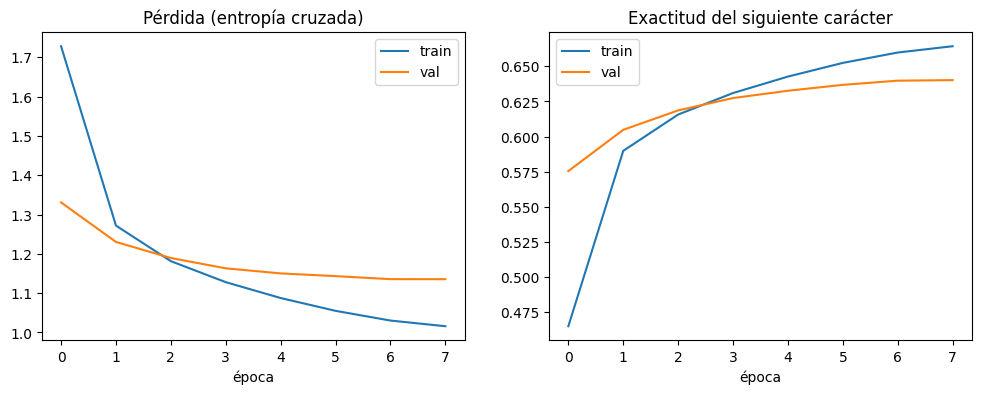

In [8]:
# Para recargar el modelo guardado:
# model = keras.models.load_model("char_llama_quijote.keras")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Pérdida (entropía cruzada)"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Exactitud del siguiente carácter"); ax[1].set_xlabel("época"); ax[1].legend()
plt.show()

## 4. Evaluación cuantitativa

Métricas estándar para modelos de lenguaje evaluadas en el conjunto de **prueba**:

* **Entropía cruzada** `H` (nats/carácter): pérdida media de predicción del siguiente carácter.
* **Perplejidad** `PPL = e^H`: número efectivo de caracteres entre los que el modelo "duda".
  Un modelo aleatorio uniforme tendría `PPL = |V|`.
* **Bits por carácter** `BPC = H / ln 2`: métrica clásica de modelos a nivel de carácter
  (≈ tasa de compresión). Los Char-RNN típicos están entre 1.3–2.0 BPC.
* **Exactitud top-1 y top-5** del siguiente carácter.

Como línea base calculamos un modelo de **unigramas** (frecuencia de caracteres) para tener una
referencia de cuánto aprende el Transformer.

In [9]:
test_loss, test_acc, test_top5 = model.evaluate(test_set, verbose=0)
ppl, bpc = math.exp(test_loss), test_loss / math.log(2)

# Línea base: unigramas de caracteres estimados en train
counts = np.bincount(encoded[:i_tr], minlength=n_tokens) + 1
p_uni = counts / counts.sum()
h_uni = -np.mean(np.log(p_uni[encoded[i_va:]]))

print(f"{'Métrica':<28}{'Char-Llama':>12}{'Unigramas':>12}")
print(f"{'Entropía cruzada (nats)':<28}{test_loss:>12.3f}{h_uni:>12.3f}")
print(f"{'Perplejidad':<28}{ppl:>12.2f}{math.exp(h_uni):>12.2f}")
print(f"{'Bits por carácter (BPC)':<28}{bpc:>12.3f}{h_uni / math.log(2):>12.3f}")
print(f"{'Exactitud top-1':<28}{test_acc:>12.3f}{p_uni.max():>12.3f}")
print(f"{'Exactitud top-5':<28}{test_top5:>12.3f}{np.sort(p_uni)[-5:].sum():>12.3f}")
print(f"Perplejidad de un modelo uniforme: {n_tokens}")

Métrica                       Char-Llama   Unigramas
Entropía cruzada (nats)            1.129       2.953
Perplejidad                         3.09       19.16
Bits por carácter (BPC)            1.629       4.260
Exactitud top-1                    0.642       0.181
Exactitud top-5                    0.905       0.514
Perplejidad de un modelo uniforme: 68


## 5. Generación de texto

Generamos de forma autorregresiva muestreando de `softmax(logits / T)`.
La **temperatura** `T` controla la diversidad: `T→0` es casi *greedy* (repetitivo y "seguro"),
`T>1` aplana la distribución (más creativo pero con más errores).

In [10]:
char2id = {c: i - 2 for i, c in enumerate(vocab) if i >= 2}

def generate(prompt, n_chars=400, temperature=0.8, seed=42):
    rng = np.random.default_rng(seed)
    ids = [char2id.get(c, 0) for c in prompt.lower()]
    for _ in range(n_chars):
        ctx = np.array([ids[-LENGTH:]], dtype="int32")
        logits = model(ctx, training=False)[0, -1].numpy().astype("float64") / temperature
        p = np.exp(logits - logits.max()); p /= p.sum()
        ids.append(int(rng.choice(len(p), p=p)))
    return "".join(vocab[i + 2] for i in ids)

prompt = "en un lugar de la mancha"
for T in [0.2, 0.8, 1.2]:
    print(f"===== Temperatura {T} =====")
    print(generate(prompt, temperature=T), "\n")

===== Temperatura 0.2 =====
en un lugar de la mancha, y el caballero de la triste figura, y el de la caballería andante estaba en la cabeza, y a la de la caballería andante estaba en la cabeza, y el cual se le había de parar a su padre y de la mano a su amo, y la duquesa y de la mancha, y el caballero de la triste figura, y de la cual se le dieron con el caballero de la triste figura, y el primero que le había de dar con el mundo, y que le diese a  

===== Temperatura 0.8 =====
en un lugar de la mancha, y el parecer de mi cuerpo sacó su amo, y no le salteó la noche, y en lo de la mano en el mundo a quien tan venturoso como el señor don quijote de la mancha, y que si su majestad y la poesía en el suelo, se acomodó en su muerte, le dijo: — vencido a vuestra merced se estaba admirado de dar palabras, porque en este mayor parte de tu carne y de ver la mano, y es muy diciendo, mientras que en ella l 

===== Temperatura 1.2 =====
en un lugar de la mancha. hidólo las barbas que me escuchada d

### Métricas sobre el texto generado

La perplejidad mide qué tan bien el modelo **predice** texto real; para valorar el texto
**generado** usamos:

* **% palabras válidas**: fracción de palabras generadas que existen en el vocabulario del
  Quijote (a nivel de carácter el modelo debe *aprender a deletrear*).
* **distinct-1 / distinct-2**: diversidad léxica (palabras y bigramas únicos).
* **Tasa de repetición de 4-gramas**: detecta bucles degenerados.

In [ ]:
def distinct_n(tokens, n):
    """Proporción de n-gramas únicos (diversidad léxica; 1.0 = sin repeticiones)."""
    grams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


corpus_words = set(re.findall(r"[a-záéíóúüñ]+", text.lower()))

def valid_word_ratio(generated):
    """% de palabras generadas que existen en el vocabulario del corpus (ortografía)."""
    words = re.findall(r"[a-záéíóúüñ]+", generated.lower())
    return sum(w in corpus_words for w in words) / max(len(words), 1)


def rep_rate(tokens, n=4):
    """% de 4-gramas repetidos dentro del mismo texto (detecta bucles)."""
    return 1 - distinct_n(tokens, n)

In [12]:
prompts = ["en un lugar de la mancha", "dijo sancho", "—señor caballero", "la hermosa dulcinea"]
rows = []
for T in [0.2, 0.8, 1.2]:
    gens = [generate(p, 200, T, seed=s)[len(p):] for s, p in enumerate(prompts)]
    toks = [w for g in gens for w in re.findall(r"\w+", g)]
    rows.append((T, np.mean([valid_word_ratio(g) for g in gens]), distinct_n(toks, 1),
                 distinct_n(toks, 2), np.mean([rep_rate(re.findall(r"\w+", g)) for g in gens])))

ref = re.findall(r"\w+", text[int(len(text) * 0.95):][:5000].lower())
print(f"{'T':>5}{'%válidas':>10}{'dist-1':>9}{'dist-2':>9}{'rep-4g':>9}")
for r in rows:
    print(f"{r[0]:>5}{r[1]:>10.3f}{r[2]:>9.3f}{r[3]:>9.3f}{r[4]:>9.3f}")
print(f"{'real':>5}{1.0:>10.3f}{distinct_n(ref[:len(toks)], 1):>9.3f}{distinct_n(ref[:len(toks)], 2):>9.3f}")

    T  %válidas   dist-1   dist-2   rep-4g
  0.2     0.987    0.405    0.713    0.039
  0.8     0.980    0.627    0.941    0.000
  1.2     0.892    0.727    0.993    0.000
 real     1.000    0.640    0.891


## 6. Conclusiones

**Resultados obtenidos** (ejecución en Colab, GPU T4, 8 épocas, 17.8 min de entrenamiento):

| Métrica (conjunto de prueba) | Char-Llama | Unigramas |
|---|---|---|
| Entropía cruzada (nats) | 1.129 | 2.953 |
| Perplejidad | **3.09** | 19.16 |
| Bits por carácter | **1.63** | 4.26 |
| Exactitud top-1 | **0.642** | 0.181 |
| Exactitud top-5 | **0.905** | 0.514 |

La pérdida de validación bajó de 1.33 (época 1) a 1.13 (época 8) sin sobreajuste. Ejemplo generado con `T = 0.2`:

> *en un lugar de la mancha, y el caballero de la triste figura, y el de la caballería andante estaba en la cabeza […] y el caballero de la triste figura…*

* El Char-Llama reduce la perplejidad de 19.2 (unigramas) a 3.09 y queda en 1.63 BPC, dentro del rango típico de los Char-RNN: el modelo
  aprende ortografía, puntuación, el uso del guion de diálogo y nombres propios (Sancho, Quijote,
  Dulcinea) solo a partir de caracteres.
* **RoPE** permite prescindir del embedding posicional absoluto y codifica posiciones relativas en
  el producto `q·k`; **RMSNorm pre-norm** y **SwiGLU** son los cambios que, según el artículo de LLaMA,
  estabilizan el entrenamiento y mejoran la calidad frente al decodificador clásico.
* **Texto generado** (palabras válidas / distinct-2 / 4-gramas repetidos): con `T = 0.2` 98.7 % /
  0.71 / 3.9 %, frases correctas pero repetitivas; con `T = 1.2` 89.2 % / 0.99 / 0 %, más variado
  pero con palabras inventadas ("descomunastro"). `T = 0.8` da el mejor equilibrio: 98.0 % de
  palabras válidas y distinct-1 = 0.63, casi igual al texto real (0.64).
* Limitación: a nivel de carácter el contexto de 128 caracteres equivale a ~20 palabras, por lo que la
  coherencia a nivel de oración/párrafo es limitada (ver Punto 2).

---
# PUNTO 2

# Punto 2 — Generación de texto a nivel de **palabra** con un Transformer tipo **Llama**

UNIVERSIDAD AUTÓNOMA DE OCCIDENTE — Inteligencia Artificial Generativa 2026-2S  
Entregable: *Modelos Generativos de Texto Basados en la Arquitectura Transformer*  
**Integrantes:** Sergio Gómez — Valeria Franco

**Objetivo:** con el mismo corpus (*Don Quijote*) y la misma arquitectura Llama del Punto 1,
modificar el pipeline para que la unidad de predicción sea la **palabra**.

### Modificaciones respecto al nivel de carácter
1. **Tokenizador de palabras**: expresión regular que separa palabras y signos de puntuación
   (`,` `.` `¿` `?` `—` y salto de línea son tokens propios, para poder generar texto bien formado).
2. **Vocabulario limitado** a las `V` palabras más frecuentes + `<unk>` (la cola larga de palabras
   raras se mapea a `<unk>`), en lugar de ~60 caracteres.
3. **Contexto** de 64 tokens (≈ 300 caracteres, más que los 128 caracteres del Punto 1).
4. **Detokenización** para reconstruir el texto a partir de tokens.
5. **Muestreo top-k** además de temperatura, para evitar palabras muy improbables.
6. Las métricas por token ya **no son comparables** con las del Punto 1; por ello se reporta además
   la **perplejidad normalizada por carácter (BPC)** para comparar ambos modelos.

In [ ]:
import os, sys, re, math, time, collections
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Modo rápido (solo para pruebas locales sin GPU): RAPIDO=1 reduce corpus y épocas
RAPIDO = os.environ.get("RAPIDO", "0") == "1"
tf.random.set_seed(42); np.random.seed(42)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Corpus: *Don Quijote de la Mancha* (Miguel de Cervantes)

Reemplazamos las obras de Shakespeare por el texto completo de **Don Quijote de la Mancha**
(Proyecto Gutenberg, libro #2000, dominio público). Es un corpus en **español** de ~2 millones
de caracteres, de tamaño comparable al de Shakespeare (~1.1 M), con diálogos y narración,
lo que lo hace adecuado para un modelo de lenguaje pequeño.

In [ ]:
url = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
filepath = tf.keras.utils.get_file("quijote.txt", url)
with open(filepath, encoding="utf-8") as f:
    raw = f.read()

# Quitamos la cabecera y la licencia de Gutenberg
start = raw.find("*** START OF"); start = raw.find("\n", start) + 1
end = raw.find("*** END OF")
text = raw[start:end].strip()
text = re.sub(r"\r", "", text)
text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)   # une las líneas cortadas a ~70 columnas
text = re.sub(r"\n{2,}", "\n", text)           # un salto de línea = cambio de párrafo
text = re.sub(r" {2,}", " ", text)
if RAPIDO:
    text = text[:200_000]
print(f"Caracteres: {len(text):,}")
print(text[5000:5600])

2225803/2225803 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Caracteres: 2,104,974
s los que llevaban a don Quijote
De la pendencia que don Quijote tuvo con el cabrero, con la rara aventura de los deceplinantes, a quien dio felice fin a costa de su sudor
Segunda parte del ingenioso caballero don Quijote de la Mancha
 Tasa
 Fee de erratas
 Aprobaciones
 Dedicatoria, al conde de Lemos
 Prólogo al lector
De lo que el cura y el barbero pasaron con don Quijote cerca de su enfermedad
Que trata de la notable pendencia que Sancho Panza tuvo con la sobrina y ama de don Quijote, con otros sujetos graciosos
Del ridículo razonamiento que pasó entre don Quijote, Sancho Panza y el bachill


## 2. Tokenización a nivel de palabra

In [ ]:
TOKEN_RE = re.compile(r"[a-záéíóúüñ]+|\d+|\n|[^\w\s]")

def tokenize(s):
    return TOKEN_RE.findall(s.lower())

tokens = tokenize(text)
freq = collections.Counter(tokens)
VOCAB_SIZE = 4000 if RAPIDO else 12000
itos = ["<unk>"] + [w for w, _ in freq.most_common(VOCAB_SIZE - 1)]
stoi = {w: i for i, w in enumerate(itos)}
encoded = np.array([stoi.get(t, 0) for t in tokens], dtype="int32")

cover = sum(c for w, c in freq.items() if w in stoi) / len(tokens)
print(f"Tokens totales: {len(tokens):,} | tipos distintos: {len(freq):,}")
print(f"Vocabulario: {len(itos):,} | cobertura del corpus: {cover:.2%} | <unk>: {1 - cover:.2%}")
print(tokens[1000:1040])

Tokens totales: 455,987 | tipos distintos: 22,969
Vocabulario: 12,000 | cobertura del corpus: 97.59% | <unk>: 2.41%
['con', 'el', 'cabrero', ',', 'con', 'la', 'rara', 'aventura', 'de', 'los', 'deceplinantes', ',', 'a', 'quien', 'dio', 'felice', 'fin', 'a', 'costa', 'de', 'su', 'sudor', '\n', 'segunda', 'parte', 'del', 'ingenioso', 'caballero', 'don', 'quijote', 'de', 'la', 'mancha', '\n', 'tasa', '\n', 'fee', 'de', 'erratas', '\n']


In [ ]:
def detokenize(toks):
    """Reconstruye texto legible: sin espacio antes de puntuación de cierre ni después de apertura."""
    out = ""
    for t in toks:
        if t == "\n":
            out += "\n"
        elif not out or out.endswith(("\n", "¿", "¡", "(", "—", "«")) or t in ",.;:!?)»":
            out += t
        else:
            out += " " + t
    return out

print(detokenize(tokens[1000:1040]))

con el cabrero, con la rara aventura de los deceplinantes, a quien dio felice fin a costa de su sudor
segunda parte del ingenioso caballero don quijote de la mancha
tasa
fee de erratas



In [ ]:
def to_dataset(sequence, length, shift=1, shuffle=False, seed=None, batch_size=64):
    ds = tf.data.Dataset.from_tensor_slices(sequence)
    ds = ds.window(length + 1, shift=shift, drop_remainder=True)
    ds = ds.flat_map(lambda w: w.batch(length + 1))
    if shuffle:
        ds = ds.shuffle(20_000, seed=seed)
    ds = ds.batch(batch_size)
    return ds.map(lambda w: (w[:, :-1], w[:, 1:])).prefetch(tf.data.AUTOTUNE)

LENGTH = 64
n = len(encoded)
i_tr, i_va = int(n * 0.90), int(n * 0.95)
train_set = to_dataset(encoded[:i_tr], LENGTH, shift=LENGTH // 8, shuffle=True, seed=42)
valid_set = to_dataset(encoded[i_tr:i_va], LENGTH, shift=LENGTH)
test_set = to_dataset(encoded[i_va:], LENGTH, shift=LENGTH)

## 3. Arquitectura Transformer tipo Llama

El Char-Transformer de clase usa la parte **decodificadora** de un Transformer "clásico"
(GPT-2/Vaswani): embeddings posicionales aprendidos, `LayerNormalization` *post-norm*,
FFN con ReLU. La familia **Llama** (Touvron et al., 2023) introduce cuatro cambios que aquí
implementamos desde cero en Keras:

| Componente | Transformer clásico | Llama (este notebook) |
|---|---|---|
| Normalización | LayerNorm (post-norm) | **RMSNorm** (pre-norm) |
| Posición | Embedding posicional absoluto sumado | **RoPE** – rotación de *queries/keys* |
| Red feed-forward | Dense → ReLU → Dense | **SwiGLU**: `W2(SiLU(W1·x) ⊙ W3·x)` |
| Sesgos (*bias*) | Sí | **No** (todas las capas lineales sin bias) |

Además la atención es **causal** (cada posición solo ve las anteriores), por lo que el modelo
es autorregresivo: `P(x_t | x_<t)`.

Es **exactamente el mismo código** del Punto 1; solo cambia `vocab_size`.

In [ ]:
import keras
from keras import layers, ops


@keras.saving.register_keras_serializable(package="llama")
class RMSNorm(layers.Layer):
    """Root Mean Square Norm: x / sqrt(mean(x^2) + eps) * g  (sin centrar ni bias)."""
    def __init__(self, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        self.scale = self.add_weight(name="scale", shape=(input_shape[-1],), initializer="ones")

    def call(self, x):
        ms = ops.mean(ops.square(x), axis=-1, keepdims=True)
        return x * ops.rsqrt(ms + self.eps) * self.scale

    def get_config(self):
        return {**super().get_config(), "eps": self.eps}


def rope(x, base=10000.0):
    """Rotary Positional Embedding. x: (batch, heads, seq, head_dim)."""
    seq_len, head_dim = ops.shape(x)[2], ops.shape(x)[3]
    half = head_dim // 2
    inv_freq = 1.0 / (base ** (ops.cast(ops.arange(half), "float32") / half))
    pos = ops.cast(ops.arange(seq_len), "float32")
    angles = ops.einsum("i,j->ij", pos, inv_freq)            # (seq, half)
    cos, sin = ops.cos(angles), ops.sin(angles)
    cos, sin = ops.cast(cos, x.dtype), ops.cast(sin, x.dtype)
    x1, x2 = x[..., :half], x[..., half:]
    return ops.concatenate([x1 * cos - x2 * sin, x1 * sin + x2 * cos], axis=-1)


@keras.saving.register_keras_serializable(package="llama")
class CausalSelfAttentionRoPE(layers.Layer):
    """Atención multi-cabeza causal con RoPE y proyecciones sin bias."""
    def __init__(self, d_model, n_heads, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.n_heads, self.dropout_rate = d_model, n_heads, dropout
        self.head_dim = d_model // n_heads
        self.wq = layers.Dense(d_model, use_bias=False)
        self.wk = layers.Dense(d_model, use_bias=False)
        self.wv = layers.Dense(d_model, use_bias=False)
        self.wo = layers.Dense(d_model, use_bias=False)
        self.drop = layers.Dropout(dropout)

    def _split(self, x, b, t):
        x = ops.reshape(x, (b, t, self.n_heads, self.head_dim))
        return ops.transpose(x, (0, 2, 1, 3))                   # (b, h, t, hd)

    def call(self, x, training=False):
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        q = rope(self._split(self.wq(x), b, t))
        k = rope(self._split(self.wk(x), b, t))
        v = self._split(self.wv(x), b, t)
        scores = ops.matmul(q, ops.transpose(k, (0, 1, 3, 2))) / ops.sqrt(ops.cast(self.head_dim, x.dtype))
        mask = ops.tril(ops.ones((t, t), dtype="bool"))          # máscara causal
        scores = ops.where(mask, scores, ops.cast(-1e9, scores.dtype))
        att = self.drop(ops.softmax(scores, axis=-1), training=training)
        out = ops.transpose(ops.matmul(att, v), (0, 2, 1, 3))
        return self.wo(ops.reshape(out, (b, t, self.d_model)))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "n_heads": self.n_heads,
                "dropout": self.dropout_rate}


@keras.saving.register_keras_serializable(package="llama")
class SwiGLU(layers.Layer):
    """FFN de Llama: W2( SiLU(W1 x) * W3 x ), sin bias."""
    def __init__(self, d_model, hidden, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.hidden = d_model, hidden
        self.w1 = layers.Dense(hidden, use_bias=False)
        self.w3 = layers.Dense(hidden, use_bias=False)
        self.w2 = layers.Dense(d_model, use_bias=False)

    def call(self, x):
        return self.w2(ops.silu(self.w1(x)) * self.w3(x))

    def get_config(self):
        return {**super().get_config(), "d_model": self.d_model, "hidden": self.hidden}


@keras.saving.register_keras_serializable(package="llama")
class LlamaBlock(layers.Layer):
    """Bloque decodificador Llama (pre-norm + conexiones residuales)."""
    def __init__(self, d_model, n_heads, ffn_hidden, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.cfg = dict(d_model=d_model, n_heads=n_heads, ffn_hidden=ffn_hidden, dropout=dropout)
        self.norm1, self.norm2 = RMSNorm(), RMSNorm()
        self.attn = CausalSelfAttentionRoPE(d_model, n_heads, dropout)
        self.ffn = SwiGLU(d_model, ffn_hidden)
        self.drop = layers.Dropout(dropout)

    def call(self, x, training=False):
        x = x + self.drop(self.attn(self.norm1(x), training=training), training=training)
        x = x + self.drop(self.ffn(self.norm2(x)), training=training)
        return x

    def get_config(self):
        return {**super().get_config(), **self.cfg}


def build_llama(vocab_size, d_model=256, n_heads=8, n_layers=6, ffn_hidden=None, dropout=0.1):
    """Modelo completo: Embedding -> N x LlamaBlock -> RMSNorm -> Dense(vocab) (logits)."""
    ffn_hidden = ffn_hidden or int(8 * d_model / 3)          # proporción usada en Llama
    inputs = keras.Input(shape=(None,), dtype="int32")
    x = layers.Embedding(vocab_size, d_model)(inputs)        # sin embedding posicional: RoPE
    x = layers.Dropout(dropout)(x)
    for i in range(n_layers):
        x = LlamaBlock(d_model, n_heads, ffn_hidden, dropout, name=f"llama_block_{i}")(x)
    x = RMSNorm(name="final_norm")(x)
    logits = layers.Dense(vocab_size, use_bias=False, name="lm_head")(x)
    return keras.Model(inputs, logits, name="llama_lm")

## 4. Entrenamiento

Con un vocabulario de 12 000 palabras la capa de salida y el embedding concentran muchos
parámetros, y el corpus (~450 k tokens) es pequeño, por lo que subimos el *dropout* a 0.2 y
usamos *early stopping* para controlar el sobreajuste.

In [ ]:
EPOCHS = 2 if RAPIDO else 12
cfg = dict(d_model=64, n_heads=4, n_layers=2) if RAPIDO else dict(d_model=256, n_heads=8, n_layers=4)
model = build_llama(len(itos), dropout=0.2, **cfg)

steps_per_epoch = sum(1 for _ in train_set)
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=EPOCHS * steps_per_epoch,
                                            warmup_target=5e-4, warmup_steps=min(500, steps_per_epoch))
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=0.1, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
model.summary()

callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("word_llama_quijote.keras", monitor="val_loss", save_best_only=True)]
t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS, callbacks=callbacks)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Model: "llama_lm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 256)      │     3,072,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, None, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_0 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_1 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_2 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ llama_block_3 (LlamaBlock)      │ (None, None, 256)      │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_norm (RMSNorm)            │ (None, None, 256)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lm_head (Dense)                 │ (None, None, 12000)    │     3,072,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,289,984 (35.44 MB)

 Trainable params: 9,289,984 (35.44 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
    802/Unknown 101s 88ms/step - accuracy: 0.1119 - loss: 6.4993 - top5: 0.2600

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


802/802 ━━━━━━━━━━━━━━━━━━━━ 107s 96ms/step - accuracy: 0.1578 - loss: 5.4746 - top5: 0.3390 - val_accuracy: 0.2079 - val_loss: 4.8174 - val_top5: 0.4187
Epoch 2/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 64s 76ms/step - accuracy: 0.2378 - loss: 4.1572 - top5: 0.4660 - val_accuracy: 0.2326 - val_loss: 4.6481 - val_top5: 0.4485
Epoch 3/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 69s 83ms/step - accuracy: 0.2752 - loss: 3.6560 - top5: 0.5199 - val_accuracy: 0.2387 - val_loss: 4.7193 - val_top5: 0.4546
Epoch 4/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 68s 82ms/step - accuracy: 0.3123 - loss: 3.2571 - top5: 0.5757 - val_accuracy: 0.2360 - val_loss: 4.8681 - val_top5: 0.4513
Epoch 5/12
802/802 ━━━━━━━━━━━━━━━━━━━━ 69s 82ms/step - accuracy: 0.3521 - loss: 2.9312 - top5: 0.6299 - val_accuracy: 0.2291 - val_loss: 5.0646 - val_top5: 0.4429
Tiempo de entrenamiento: 6.3 min


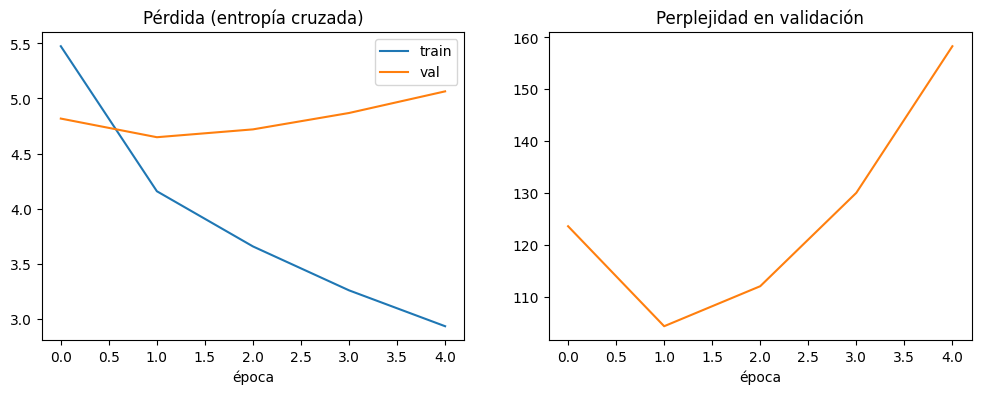

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Pérdida (entropía cruzada)"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(np.exp(history.history["val_loss"]), color="C1")
ax[1].set_title("Perplejidad en validación"); ax[1].set_xlabel("época")
plt.show()

## 5. Evaluación cuantitativa

* **Perplejidad por palabra** `PPL = e^H` en prueba, comparada con líneas base de
  **unigramas** y **bigramas** (con suavizado de Laplace).
* **Exactitud top-1 / top-5** de la siguiente palabra.
* **Tasa de `<unk>`** en prueba (cuánto texto queda fuera del vocabulario).
* **BPC equivalente** = `H_total / (n_caracteres · ln 2)`: normaliza la pérdida por carácter para
  comparar con el modelo del Punto 1 (aproximación: incluye la penalización de los `<unk>`).

In [ ]:
test_loss, test_acc, test_top5 = model.evaluate(test_set, verbose=0)
test_ids = encoded[i_va:]
V = len(itos)

# Línea base de unigramas y bigramas (Laplace) estimadas en train
tr = encoded[:i_tr]
uni = np.bincount(tr, minlength=V) + 1.0; uni /= uni.sum()
h_uni = -np.mean(np.log(uni[test_ids]))
big = collections.Counter(zip(tr[:-1], tr[1:])); ctx = np.bincount(tr, minlength=V)
h_bi = -np.mean([math.log((big[(a, b)] + 1) / (ctx[a] + V)) for a, b in zip(test_ids[:-1], test_ids[1:])])

n_eval_tokens = (len(test_ids) - 1) // LENGTH * LENGTH
chars_per_token = len(detokenize([itos[i] for i in test_ids])) / len(test_ids)
bpc_equiv = test_loss / (chars_per_token * math.log(2))

print(f"{'Métrica':<26}{'Word-Llama':>12}{'Bigramas':>11}{'Unigramas':>11}")
print(f"{'Entropía cruzada (nats)':<26}{test_loss:>12.3f}{h_bi:>11.3f}{h_uni:>11.3f}")
print(f"{'Perplejidad por palabra':<26}{math.exp(test_loss):>12.1f}{math.exp(h_bi):>11.1f}{math.exp(h_uni):>11.1f}")
print(f"{'Exactitud top-1':<26}{test_acc:>12.3f}")
print(f"{'Exactitud top-5':<26}{test_top5:>12.3f}")
print(f"Tasa de <unk> en prueba: {(test_ids == 0).mean():.2%}")
print(f"BPC equivalente: {bpc_equiv:.3f}  (≈{chars_per_token:.2f} caracteres por token)")

Métrica                     Word-Llama   Bigramas  Unigramas
Entropía cruzada (nats)          4.571      6.767      6.091
Perplejidad por palabra           96.7      868.7      441.8
Exactitud top-1                  0.239
Exactitud top-5                  0.458
Tasa de <unk> en prueba: 2.56%
BPC equivalente: 1.462  (≈4.51 caracteres por token)


## 6. Generación de texto (temperatura + top-k)

En el muestreo se **prohíbe `<unk>`** y se restringe a las `k` palabras más probables.

In [ ]:
def generate(prompt, n_words=120, temperature=0.8, top_k=40, seed=42):
    rng = np.random.default_rng(seed)
    ids = [stoi.get(t, 0) for t in tokenize(prompt)]
    for _ in range(n_words):
        ctx = np.array([ids[-LENGTH:]], dtype="int32")
        logits = model(ctx, training=False)[0, -1].numpy().astype("float64") / temperature
        logits[0] = -np.inf                                   # nunca generar <unk>
        top = np.argsort(logits)[-top_k:]
        p = np.exp(logits[top] - logits[top].max()); p /= p.sum()
        ids.append(int(top[rng.choice(len(top), p=p)]))
    return detokenize([itos[i] for i in ids])

prompt = "en un lugar de la mancha"
for T in [0.3, 0.8, 1.1]:
    print(f"===== Temperatura {T}, top-k 40 =====")
    print(generate(prompt, temperature=T), "\n")

===== Temperatura 0.3, top-k 40 =====
en un lugar de la mancha, y, en todo eso, se me ha de dar a entender que me ha de dar a entender que no me ha de llevar el gobierno de mi señor don quijote, y no me acuerdo, sino que no me acuerdo, ni él se le ha hecho, ni aun de otra cosa que en la mitad de la tierra.
—así es —dijo don quijote —, y no hay más que decir que yo, que yo no me acuerdo, ni yo soy caballero andante, ni sé qué es lo que yo me ha dicho, y no sé yo que no me acuerdo, ni aun de 

===== Temperatura 0.8, top-k 40 =====
en un lugar de la mancha, en la cual el duque se le vio con mucha priesa, y luego a sancho la duquesa, que en la venta se halló, o era la más hermosa, y la hija del señor don quijote, que ya le había dado por cierto que aquel encantador hacía, y que no había de pasar de la ciudad, y, aunque se había más de dos leguas, ya tenía más que la sangre de su hija, el que estaba puesta en los estribos, y, volviendo al pie de los paveses, dijo:
—¡oh, señora de la caballe

### Métricas sobre el texto generado

* **distinct-1 / distinct-2** y **repetición de 4-gramas** (diversidad / bucles).
* **% de bigramas vistos**: fracción de bigramas generados que aparecen en el corpus de
  entrenamiento — mide fluidez local (muy cerca de 1.0 + distinct bajo = el modelo *copia*;
  muy bajo = combinaciones agramaticales).
* **Auto-perplejidad con el modelo de bigramas**: qué tan "plausible" es el texto generado para un
  modelo independiente (menor = más fluido).

In [ ]:
def distinct_n(tokens, n):
    """Proporción de n-gramas únicos (diversidad léxica; 1.0 = sin repeticiones)."""
    grams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


corpus_words = set(re.findall(r"[a-záéíóúüñ]+", text.lower()))

def valid_word_ratio(generated):
    """% de palabras generadas que existen en el vocabulario del corpus (ortografía)."""
    words = re.findall(r"[a-záéíóúüñ]+", generated.lower())
    return sum(w in corpus_words for w in words) / max(len(words), 1)


def rep_rate(tokens, n=4):
    """% de 4-gramas repetidos dentro del mismo texto (detecta bucles)."""
    return 1 - distinct_n(tokens, n)

In [ ]:
train_bigrams = set(zip(tr[:-1], tr[1:]))

def gen_metrics(gen_text):
    ids = [stoi.get(t, 0) for t in tokenize(gen_text)]
    pairs = list(zip(ids[:-1], ids[1:]))
    seen = np.mean([p in train_bigrams for p in pairs])
    h = -np.mean([math.log((big[p] + 1) / (ctx[p[0]] + V)) for p in pairs])
    return seen, math.exp(h)

prompts = ["en un lugar de la mancha", "dijo sancho", "—señor caballero", "la hermosa dulcinea"]
print(f"{'T':>5}{'dist-1':>9}{'dist-2':>9}{'rep-4g':>9}{'%bigr.vistos':>14}{'PPL-bigr':>10}")
for T in [0.3, 0.8, 1.2]:
    gens = [generate(p, 100, T, seed=s)[len(p):] for s, p in enumerate(prompts)]
    toks = [w for g in gens for w in tokenize(g)]
    m = np.array([gen_metrics(g) for g in gens]).mean(axis=0)
    print(f"{T:>5}{distinct_n(toks, 1):>9.3f}{distinct_n(toks, 2):>9.3f}"
          f"{np.mean([rep_rate(tokenize(g)) for g in gens]):>9.3f}{m[0]:>14.3f}{m[1]:>10.1f}")

real = detokenize([itos[i] for i in test_ids[:400]])
rt = tokenize(real); m = gen_metrics(real)
print(f"{'real':>5}{distinct_n(rt, 1):>9.3f}{distinct_n(rt, 2):>9.3f}{rep_rate(rt):>9.3f}{m[0]:>14.3f}{m[1]:>10.1f}")

    T   dist-1   dist-2   rep-4g  %bigr.vistos  PPL-bigr
  0.3    0.217    0.464    0.134         0.997     109.4
  0.8    0.375    0.797    0.000         0.980     253.8
  1.2    0.438    0.875    0.000         0.942     424.0
 real    0.475    0.877    0.020         0.764    1203.1


## 7. Conclusiones y comparación carácter vs. palabra

Resultados obtenidos en Colab con GPU T4 (EarlyStopping detuvo el entrenamiento en la época 5 de 12
y restauró los pesos de la época 2, la de menor `val_loss` = 4.648; tiempo total 6.3 min).

| Métrica (prueba) | Word-Llama | Bigramas (Laplace) | Unigramas |
|---|---|---|---|
| Entropía cruzada (nats) | **4.571** | 6.767 | 6.091 |
| Perplejidad por palabra | **96.7** | 868.7 | 441.8 |
| Exactitud top-1 / top-5 | **0.239 / 0.458** | — | — |

| Aspecto | Nivel carácter (Punto 1) | Nivel palabra (Punto 2) |
|---|---|---|
| Vocabulario | ~60 símbolos | 12 000 palabras + `<unk>` (cobertura 97.6 %) |
| Contexto efectivo | 128 caracteres (~20 palabras) | 64 tokens (~300 caracteres) |
| BPC en prueba | 1.63 | **1.46** (equivalente, ≈4.51 caracteres por token) |
| Ortografía | Debe aprenderla (puede inventar palabras) | Garantizada (solo palabras reales) |
| Palabras raras | Siempre representables | Se pierden en `<unk>` (2.56 % en prueba) |
| Parámetros | Concentrados en los bloques | 6.1 M de 9.3 M en embedding + `lm_head` |
| Sobreajuste | Bajo | Alto: `val_loss` sube desde la época 3 |

* **El modelo de palabras supera con claridad a los n-gramas**: perplejidad 96.7 frente a 441.8
  (unigramas). El modelo de bigramas queda peor que el de unigramas porque el suavizado de Laplace
  reparte demasiada probabilidad entre 12 000² pares que casi nunca aparecen.
* **En BPC equivalente (1.46) el modelo de palabras queda por debajo del Char-Llama (1.63)**: el
  contexto de 64 palabras cubre más texto que los 128 caracteres. La comparación es aproximada,
  porque el 2.56 % de `<unk>` le ahorra al modelo de palabras predecir las palabras raras.
* **El sobreajuste es el límite principal**: la exactitud de entrenamiento sigue subiendo
  (0.35 en la época 5) mientras la de validación se estanca entre 0.23 y 0.24. Con ~450 k tokens no hay datos
  suficientes para un vocabulario de 12 000 palabras.
* **Texto generado**: a T = 0.8 no hay 4-gramas repetidos y distinct-2 = 0.80, cerca del texto real
  (0.88). A T = 0.3 aparecen bucles (13 % de 4-gramas repetidos). El 98 % de los bigramas
  generados a T = 0.8 ya existen en el entrenamiento, frente a 76 % en el texto real de prueba: el
  modelo tiende a recombinar frases vistas en lugar de crear combinaciones nuevas.
* El punto intermedio natural es la **tokenización por subpalabras (BPE/SentencePiece)**, que es la
  que usa Llama real: vocabulario abierto sin `<unk>` y secuencias cortas.

---
# PUNTO 3

# Punto 3 — RAG (*Retrieval-Augmented Generation*) implementado con **Ollama**

UNIVERSIDAD AUTÓNOMA DE OCCIDENTE — Inteligencia Artificial Generativa 2026-2S  
Entregable: *Modelos Generativos de Texto Basados en la Arquitectura Transformer*  
**Integrantes:** Sergio Gómez — Valeria Franco

## Problema a solucionar

Estudiantes del curso necesitan un **asistente de consulta sobre los artículos fundacionales de
los LLM** que vemos en clase. Un LLM pequeño ejecutado localmente (Llama 3.2 3B) no conoce los
detalles exactos de estos artículos (hiperparámetros, cifras, definiciones) y tiende a
**alucinarlos**. Con RAG el modelo responde **apoyándose en fragmentos recuperados** de los PDFs y
citando la fuente.

**Base de contexto (3 documentos PDF, arXiv):**
1. Vaswani et al. (2017) — *Attention Is All You Need* (arXiv:1706.03762)
2. Touvron et al. (2023) — *LLaMA: Open and Efficient Foundation Language Models* (arXiv:2302.13971)
3. Lewis et al. (2020) — *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (arXiv:2005.11401)

**Pipeline:** PDF → texto → *chunks* con solapamiento → embeddings (`nomic-embed-text` vía Ollama)
→ búsqueda por similitud coseno (top-k) → *prompt* con contexto → generación (`llama3.2:3b` vía Ollama).

**Evaluación:** conjunto de 12 preguntas con respuesta de referencia y documento fuente conocido;
se evalúa la **recuperación** (Hit@k, MRR, precisión de contexto) y la **generación**
(exactitud por palabras clave, similitud semántica, ROUGE-L, *faithfulness* y relevancia con
LLM-como-juez), comparando **RAG vs. el mismo LLM sin contexto**.

> Ejecutar en Colab con **GPU (T4)**.

## 1. Instalación y arranque de Ollama en Colab

In [1]:
!sudo apt-get -qq install -y zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!pip -q install pypdf rouge-score

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 12.7 MB/s eta 0:00:00


In [2]:
import subprocess, time, os
# Lanzamos el servidor de Ollama en segundo plano
server = subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
time.sleep(5)

LLM_MODEL = "llama3.2:3b"          # generador
EMB_MODEL = "nomic-embed-text"     # modelo de embeddings
!ollama pull {LLM_MODEL}
!ollama pull {EMB_MODEL}
!ollama list



NAME                       ID              SIZE      MODIFIED               
nomic-embed-text:latest    0a109f422b47    274 MB    Less than a second ago    
llama3.2:3b                a80c4f17acd5    2.0 GB    5 seconds ago             


In [3]:
import re, json, math, urllib.request
import numpy as np
import requests
from pypdf import PdfReader

OLLAMA = "http://localhost:11434"

def embed(texts):
    """Embeddings con Ollama (/api/embed acepta lotes)."""
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMB_MODEL, "input": texts})
    r.raise_for_status()
    e = np.array(r.json()["embeddings"], dtype="float32")
    return e / np.linalg.norm(e, axis=1, keepdims=True)     # normalizamos para coseno

def chat(prompt, system=None, temperature=0.0):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    r = requests.post(f"{OLLAMA}/api/chat", json={"model": LLM_MODEL, "messages": msgs, "stream": False,
                                                  "options": {"temperature": temperature, "num_ctx": 4096}})
    r.raise_for_status()
    return r.json()["message"]["content"].strip()

print(chat("Responde solo 'listo'."))

Listo.


## 2. Base de contexto: descarga y lectura de los 3 PDFs

In [4]:
DOCS = {
    "attention": ("Attention Is All You Need", "https://arxiv.org/pdf/1706.03762"),
    "llama": ("LLaMA: Open and Efficient Foundation Language Models", "https://arxiv.org/pdf/2302.13971"),
    "rag": ("Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks", "https://arxiv.org/pdf/2005.11401"),
}
os.makedirs("docs", exist_ok=True)
pages = []                                   # (doc_id, n_página, texto)
for doc_id, (title, url) in DOCS.items():
    path = f"docs/{doc_id}.pdf"
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    for i, page in enumerate(PdfReader(path).pages):
        t = re.sub(r"\s+", " ", page.extract_text() or "").strip()
        if t:
            pages.append((doc_id, i + 1, t))
    print(f"{doc_id:<10} {sum(p[0] == doc_id for p in pages):>3} páginas — {title}")

attention   15 páginas — Attention Is All You Need
llama       27 páginas — LLaMA: Open and Efficient Foundation Language Models
rag         19 páginas — Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks


## 3. Fragmentación (*chunking*) e indexación

Fragmentos de ~800 caracteres con solapamiento de 150, cortando en límites de oración cuando es
posible. Cada fragmento conserva su documento y página para poder **citar la fuente**.

In [5]:
def chunk_text(t, size=800, overlap=150):
    chunks, start = [], 0
    while start < len(t):
        end = min(start + size, len(t))
        if end < len(t):                                   # retrocede al último punto
            cut = t.rfind(". ", start + size // 2, end)
            end = cut + 1 if cut != -1 else end
        chunks.append(t[start:end].strip())
        if end == len(t):
            break
        start = end - overlap
    return chunks

chunks = [{"doc": d, "page": p, "text": c} for d, p, t in pages for c in chunk_text(t)]
print("Fragmentos:", len(chunks))

# Embeddings por lotes (nomic-embed-text usa prefijos de tarea)
E = np.vstack([embed([f"search_document: {c['text']}" for c in chunks[i:i + 32]])
               for i in range(0, len(chunks), 32)])
print("Matriz de embeddings:", E.shape)

Fragmentos: 351
Matriz de embeddings: (351, 768)


## 4. Recuperación y generación aumentada

In [6]:
def retrieve(question, k=4):
    q = embed([f"search_query: {question}"])[0]
    sims = E @ q
    top = np.argsort(-sims)[:k]
    return [{**chunks[i], "score": float(sims[i])} for i in top]

SYSTEM = ("Eres un asistente que responde preguntas sobre artículos de investigación en IA. "
          "Responde SOLO con la información del CONTEXTO. Si el contexto no contiene la respuesta, "
          "di 'No lo sé con la información disponible'. Responde en español, de forma breve, y cita "
          "las fuentes como [doc p.N].")

def rag_answer(question, k=4):
    ctx = retrieve(question, k)
    context = "\n\n".join(f"[{c['doc']} p.{c['page']}] {c['text']}" for c in ctx)
    prompt = f"CONTEXTO:\n{context}\n\nPREGUNTA: {question}\nRESPUESTA:"
    return chat(prompt, SYSTEM), ctx

def no_rag_answer(question):
    return chat(f"Responde en español, de forma breve.\nPREGUNTA: {question}\nRESPUESTA:")

q = "¿Qué función de activación usa LLaMA en la red feed-forward y por qué?"
ans, ctx = rag_answer(q)
print(ans, "\n\nFuentes:", [(c["doc"], c["page"], round(c["score"], 3)) for c in ctx])

No lo sé con la información disponible. 

Fuentes: [('llama', 7, 0.56), ('llama', 1, 0.551), ('llama', 7, 0.549), ('llama', 7, 0.543)]


## 5. Conjunto de evaluación

12 preguntas (4 por documento) con **respuesta de referencia**, **palabras clave** que una
respuesta correcta debe contener y **documento fuente**. Incluimos además 2 preguntas
*fuera de dominio* para medir si el sistema se abstiene en lugar de alucinar.

In [7]:
EVAL = [
    # (pregunta, doc_fuente, respuesta_referencia, palabras_clave)
    ("¿Cuántas cabezas de atención usa el modelo Transformer base?", "attention",
     "El modelo base usa 8 cabezas de atención paralelas (h = 8).", ["8"]),
    ("¿Cuál es la dimensión d_model del Transformer base?", "attention",
     "d_model = 512.", ["512"]),
    ("¿Qué BLEU obtuvo el Transformer grande en la traducción inglés-alemán WMT 2014?", "attention",
     "Obtuvo 28.4 BLEU en WMT 2014 inglés-alemán.", ["28.4"]),
    ("¿Por qué se escala el producto punto por 1/sqrt(d_k) en la atención?", "attention",
     "Porque para valores grandes de d_k los productos punto crecen y empujan el softmax a regiones "
     "con gradientes muy pequeños; escalar por 1/sqrt(d_k) lo contrarresta.", ["gradient", "softmax"]),
    ("¿Qué tipo de normalización usa LLaMA y dónde la aplica?", "llama",
     "Usa RMSNorm aplicada a la entrada de cada subcapa (pre-normalización).", ["rmsnorm"]),
    ("¿Qué función de activación usa LLaMA en la red feed-forward?", "llama",
     "Usa la activación SwiGLU (en lugar de ReLU), con dimensión 2/3·4d.", ["swiglu"]),
    ("¿Qué tipo de codificación posicional usa LLaMA?", "llama",
     "Usa embeddings posicionales rotatorios (RoPE) en lugar de embeddings posicionales absolutos.", ["rota", "rope"]),
    ("¿Con cuántos tokens se entrenaron los modelos LLaMA de 33B y 65B?", "llama",
     "Se entrenaron con 1.4 billones (trillion) de tokens.", ["1.4"]),
    ("¿Qué dos componentes combina el modelo RAG?", "rag",
     "Combina una memoria paramétrica (un generador seq2seq preentrenado, BART) y una memoria no "
     "paramétrica (un índice denso de Wikipedia accedido con un recuperador neuronal, DPR).", ["bart", "wikipedia"]),
    ("¿Cuál es la diferencia entre RAG-Sequence y RAG-Token?", "rag",
     "RAG-Sequence usa el mismo documento recuperado para generar toda la secuencia; RAG-Token puede "
     "usar un documento distinto para cada token.", ["token", "secuencia"]),
    ("¿Qué recuperador usa RAG?", "rag",
     "Usa Dense Passage Retriever (DPR) con un codificador de consultas basado en BERT y búsqueda MIPS.", ["dpr"]),
    ("¿Qué modelo generador usa RAG?", "rag",
     "Usa BART-large como generador seq2seq.", ["bart"]),
]
OUT_OF_DOMAIN = ["¿Cuál es la capital de Mongolia según estos artículos?",
                 "¿Qué resultados obtiene GPT-4 en el examen de abogacía según los documentos?"]

## 6. Evaluación de la recuperación

Para cada pregunta, un fragmento se considera **relevante** si pertenece al documento fuente
**y** contiene alguna de las palabras clave de la respuesta.

* **Hit@k**: % de preguntas con al menos un fragmento relevante en el top-k.
* **MRR** (*Mean Reciprocal Rank*): promedio de `1/posición` del primer fragmento relevante.
* **Precisión de contexto@k**: fracción de los k fragmentos que son relevantes.
* **Doc-Hit@1**: el primer fragmento proviene del documento correcto.

In [8]:
def strip_accents(s):
    import unicodedata
    return "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn")

# Palabras clave en inglés equivalentes para buscar dentro de los PDFs (escritos en inglés)
KW_EN = {"secuencia": "sequence"}

def is_relevant(c, doc, kws):
    t = strip_accents(c["text"])
    return c["doc"] == doc and any(KW_EN.get(k, k) in t for k in kws)

K = 4
hits, rr, prec, doc1 = [], [], [], []
for q, doc, _, kws in EVAL:
    ctx = retrieve(q, K)
    rel = [is_relevant(c, doc, kws) for c in ctx]
    hits.append(any(rel)); prec.append(np.mean(rel)); doc1.append(ctx[0]["doc"] == doc)
    rr.append(1 / (rel.index(True) + 1) if any(rel) else 0.0)

print(f"Hit@{K}: {np.mean(hits):.2f} | MRR: {np.mean(rr):.2f} | "
      f"Precisión de contexto@{K}: {np.mean(prec):.2f} | Doc-Hit@1: {np.mean(doc1):.2f}")

Hit@4: 0.58 | MRR: 0.41 | Precisión de contexto@4: 0.25 | Doc-Hit@1: 0.92


## 7. Evaluación de la generación: RAG vs. sin RAG

* **Exactitud por palabras clave**: la respuesta contiene la(s) palabra(s) clave (p. ej. "512", "SwiGLU").
* **Similitud semántica** coseno entre los embeddings de la respuesta y de la referencia.
* **ROUGE-L (F1)** respecto a la referencia (solapamiento léxico).
* **LLM-como-juez** (mismo modelo, temperatura 0), escala 1–5:
  * **Corrección** frente a la referencia.
  * **Fidelidad (*faithfulness*)**: ¿la respuesta está sustentada por el contexto recuperado? (solo RAG)
* **Abstención** en preguntas fuera de dominio.

In [9]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rougeL"])

def judge(instruction):
    out = chat(instruction + "\nResponde ÚNICAMENTE con un número entero del 1 al 5.")
    m = re.search(r"[1-5]", out)
    return int(m.group()) if m else 1

def correctness(q, ref, ans):
    return judge(f"Pregunta: {q}\nRespuesta de referencia: {ref}\nRespuesta evaluada: {ans}\n"
                 "¿Qué tan correcta es la respuesta evaluada respecto a la referencia? (5 = totalmente correcta)")

def faithfulness(ans, ctx):
    context = "\n".join(c["text"] for c in ctx)
    return judge(f"Contexto:\n{context}\n\nRespuesta: {ans}\n"
                 "¿Qué tanto de la respuesta está respaldado por el contexto? (5 = todo respaldado, 1 = inventado)")

def keyword_hit(ans, kws):
    a = strip_accents(ans)
    return float(any(strip_accents(k) in a or KW_EN.get(k, "~") in a for k in kws))

results = []
for q, doc, ref, kws in EVAL:
    ans_rag, ctx = rag_answer(q)
    ans_base = no_rag_answer(q)
    e_ref = embed([ref])[0]
    row = {"q": q}
    for name, ans in [("rag", ans_rag), ("base", ans_base)]:
        row[f"{name}_ans"] = ans
        row[f"{name}_kw"] = keyword_hit(ans, kws)
        row[f"{name}_sim"] = float(embed([ans])[0] @ e_ref)
        row[f"{name}_rougeL"] = scorer.score(ref, ans)["rougeL"].fmeasure
        row[f"{name}_correct"] = correctness(q, ref, ans)
    row["rag_faith"] = faithfulness(ans_rag, ctx)
    results.append(row)
    print(f"· {q}\n   RAG : {ans_rag[:160]}\n   BASE: {ans_base[:160]}\n")

· ¿Cuántas cabezas de atención usa el modelo Transformer base?
   RAG : Según la información proporcionada en el contexto, el modelo Transformer base utiliza 8 cabezas de atención.
   BASE: El modelo Transformer base utiliza 12 capas de atención.

· ¿Cuál es la dimensión d_model del Transformer base?
   RAG : Según la información proporcionada en el contexto, la dimensión d_model del Transformer base es de 512.
   BASE: La dimensión d_model del Transformer base es de 768.

· ¿Qué BLEU obtuvo el Transformer grande en la traducción inglés-alemán WMT 2014?
   RAG : El Transformer grande obtuvo un BLEU de 28.4 en la traducción inglés-alemán WMT 2014.
   BASE: Bleu 04 obtuvo el Transformer grande en la traducción inglés-alemán WMT 2014.

· ¿Por qué se escala el producto punto por 1/sqrt(d_k) en la atención?
   RAG : Según [attention p.4], se escala el producto punto por 1/√dk para "counteractar el efecto de que los gradientes del softmax se vuelven extremadamente pequeños e
   BASE: La esca

In [10]:
import pandas as pd
df = pd.DataFrame(results)
summary = pd.DataFrame({
    "Exactitud palabras clave": [df.rag_kw.mean(), df.base_kw.mean()],
    "Similitud semántica": [df.rag_sim.mean(), df.base_sim.mean()],
    "ROUGE-L F1": [df.rag_rougeL.mean(), df.base_rougeL.mean()],
    "Corrección juez (1-5)": [df.rag_correct.mean(), df.base_correct.mean()],
    "Fidelidad juez (1-5)": [df.rag_faith.mean(), np.nan],
}, index=["RAG (llama3.2:3b + contexto)", "Sin RAG (llama3.2:3b)"]).round(3)
summary

,Exactitud palabras clave,Similitud semántica,ROUGE-L F1,Corrección juez (1-5),Fidelidad juez (1-5)
RAG (llama3.2:3b + contexto),0.500,0.672,0.212,3.75,3.583
Sin RAG (llama3.2:3b),0.083,0.676,0.210,2.75,NaN


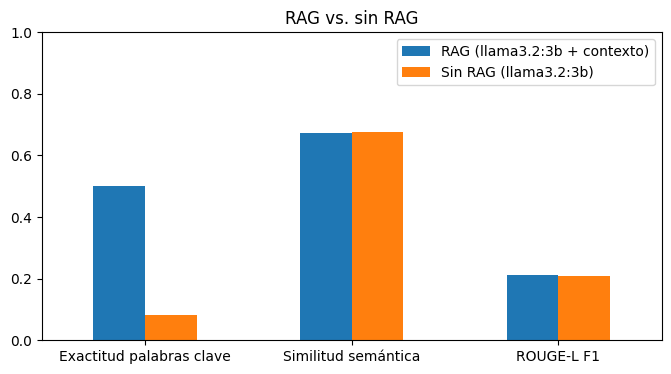

In [11]:
import matplotlib.pyplot as plt
cols = ["Exactitud palabras clave", "Similitud semántica", "ROUGE-L F1"]
summary[cols].T.plot(kind="bar", figsize=(8, 4), rot=0, title="RAG vs. sin RAG")
plt.ylim(0, 1); plt.show()

In [12]:
# Abstención ante preguntas cuya respuesta NO está en los documentos
ABST = ["no lo sé", "no lo se", "no se menciona", "no contiene", "no hay información", "no tengo"]
for q in OUT_OF_DOMAIN:
    ans, _ = rag_answer(q)
    print(f"· {q}\n  → {ans}\n  Se abstiene: {any(a in ans.lower() for a in ABST)}\n")

· ¿Cuál es la capital de Mongolia según estos artículos?
  → No lo sé con la información disponible.
  Se abstiene: True

· ¿Qué resultados obtiene GPT-4 en el examen de abogacía según los documentos?
  → No lo sé con la información disponible.
  Se abstiene: True



## 8. Conclusiones

Resultados obtenidos en Colab con GPU T4, `llama3.2:3b` y `nomic-embed-text` (351 fragmentos).

| Métrica | RAG | Sin RAG |
|---|---|---|
| Exactitud por palabras clave | **0.500** | 0.083 |
| Similitud semántica con la referencia | 0.672 | 0.676 |
| ROUGE-L F1 | 0.212 | 0.210 |
| Corrección según el juez (1-5) | **3.75** | 2.75 |
| Fidelidad al contexto según el juez (1-5) | 3.58 | — |

Recuperación (k = 4): Hit@4 = 0.58, MRR = 0.41, precisión de contexto@4 = 0.25, Doc-Hit@1 = 0.92.

* **RAG multiplica por 6 la exactitud en datos concretos** (0.50 frente a 0.08). Sin contexto el
  modelo inventa cifras: dice 768 en lugar de 512 para `d_model`, "12 capas de atención" en lugar de 8 cabezas, y
  confunde RAG con un "Recurrent Active Graph". Con contexto acierta 512, 8 cabezas y 28.4 BLEU.
* **La recuperación es el cuello de botella.** El documento correcto aparece primero en el 92 % de
  las preguntas, pero el fragmento exacto con la respuesta solo está entre los 4 recuperados en el
  58 %. Las 4 preguntas sobre LLaMA (RMSNorm, SwiGLU, RoPE, 1.4T tokens) fallaron por esto: el
  modelo recibió fragmentos que no contenían el dato y respondió "No lo sé". Es el
  comportamiento correcto (no alucina), pero son respuestas perdidas. Una búsqueda híbrida
  (BM25 + densa), un *re-ranker* o fragmentos más pequeños deberían corregirlo.
* **La similitud semántica y ROUGE-L casi no distinguen** los dos sistemas: una respuesta con la
  cifra equivocada se parece tanto a la referencia como una correcta. Por eso la exactitud por
  palabras clave y el juez son las métricas que muestran la diferencia.
* **Abstención:** ante las 2 preguntas fuera de los documentos (capital de Mongolia, GPT-4 en el
  examen de abogacía) el sistema respondió "No lo sé" en ambos casos.
* **Limitaciones:** el juez es el mismo modelo de 3B (sesgo de autoevaluación) y alguna respuesta
  con RAG sigue siendo imprecisa (p. ej. nombra RAG-Sequence como "generador" en vez de BART);
  el conjunto de 12 preguntas es pequeño. Para una evaluación más robusta se podría usar RAGAS con
  un juez más grande.